# ASTRA — Milestone 2: Exploratory Data Analysis

**Scope: EDA only.** No model training, no train/test split, no feature
engineering for training, no leakage-column removal from the dataset
(only exclusion from analysis/recommendations).

Every output in this notebook comes from actually running the cells
against the real `DataCoSupplyChainDataset.csv`.

## 1. Objective

**Research question:** Using information legitimately available when
an order's shipping decision is being planned, can ASTRA estimate the
probability that the order will eventually experience late delivery?

**Target:** `Late_delivery_risk` (0 = not late, 1 = late) — unchanged
from Milestone 1.

## 2. Prediction contract

**Prediction moment:** order / shipping-planning time — after the order
is placed and its shipping mode/window is decided, before the shipment
occurs.

Every column has been classified into AVAILABLE / UNCERTAIN /
UNAVAILABLE-LEAKY / TARGET / REDUNDANT / PRIVACY-EXCLUDED /
LOW-INFORMATION — full table and reasoning in
`docs/prediction_contract.md`. This notebook only analyzes columns
against the target where that classification supports it.

## 3. Load dataset

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.data.loaders import load_csv
from src.data.eda_helpers import group_rate_table
from src.utils.config import load_config, resolve_path

config = load_config()
raw_data_dir = resolve_path(config["paths"]["data_raw"])
figures_dir = resolve_path(config["paths"]["artifacts_figures"])

df = load_csv(raw_data_dir / "DataCoSupplyChainDataset.csv")
od = pd.to_datetime(df["order date (DateOrders)"], errors="coerce")
df["order_year"] = od.dt.year
df["order_month"] = od.dt.month
df["order_dow"] = od.dt.day_name()
df["order_hour"] = od.dt.hour
df.shape

2026-09-25 19:01:58 | WARNING  | src.data.loaders | Failed to decode DataCoSupplyChainDataset.csv with encoding=utf-8, trying next fallback.


2026-09-25 19:02:00 | INFO     | src.data.loaders | Loaded DataCoSupplyChainDataset.csv: 180519 rows x 53 columns (encoding=latin-1)


(180519, 57)

## 4. Target distribution

Late_delivery_risk
0    81542
1    98977
Name: count, dtype: int64
Late_delivery_risk
0    45.17
1    54.83
Name: proportion, dtype: float64


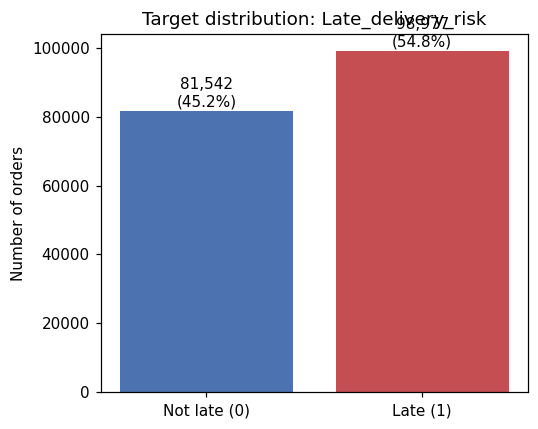

In [2]:
counts = df["Late_delivery_risk"].value_counts().sort_index()
pct = (df["Late_delivery_risk"].value_counts(normalize=True) * 100).round(2).sort_index()
print(counts)
print(pct)
display(Image(filename=str(figures_dir / "fig01_target_distribution.png")))

## 5. Leakage reminder

`Days for shipping (real)`, `shipping date (DateOrders)`, and
`Delivery Status` are excluded from all feature-vs-target analysis
below **except** the dedicated leakage demonstration in Section 11,
where they are used specifically to show *why* they're leaky.

## 6. Data-quality / redundancy summary

Confirmed redundant pairs (exact row-wise equality) — three carried
over from Milestone 1, three new ones found this milestone:

In [3]:
dup_pairs = [
    ("Order Customer Id", "Customer Id"),
    ("Product Category Id", "Category Id"),
    ("Order Item Cardprod Id", "Product Card Id"),
    ("Sales per customer", "Order Item Total"),
    ("Order Profit Per Order", "Benefit per order"),
    ("Product Price", "Order Item Product Price"),
]
for a, b in dup_pairs:
    print(f"{a} == {b}: {(df[a].round(2) == df[b].round(2)).all()}")

Order Customer Id == Customer Id: True
Product Category Id == Category Id: True
Order Item Cardprod Id == Product Card Id: True
Sales per customer == Order Item Total: True
Order Profit Per Order == Benefit per order: True
Product Price == Order Item Product Price: True


Constant / empty columns (no predictive value regardless of leakage status):

In [4]:
for col in ["Customer Email", "Customer Password", "Product Status", "Product Description"]:
    print(col, "-> unique values:", df[col].nunique(dropna=True), ", missing %:", round(df[col].isna().mean()*100, 2))

Customer Email -> unique values: 1 , missing %: 0.0
Customer Password -> unique values: 1 , missing %: 0.0
Product Status -> unique values: 1 , missing %: 0.0
Product Description -> unique values: 0 , missing %: 100.0


## 7. Categorical analysis

For each AVAILABLE categorical feature: sample count, late count, and
late-delivery rate.

In [5]:
for col in ["Shipping Mode", "Market", "Customer Segment", "Type"]:
    print(f"--- {col} ---")
    print(group_rate_table(df, col, "Late_delivery_risk").to_string(index=False))
    print()

--- Shipping Mode ---
 Shipping Mode  sample_count  positive_count  positive_rate  low_sample_warning
Standard Class        107752           41023         0.3807               False
  Second Class         35216           26987         0.7663               False
   First Class         27814           26513         0.9532               False
      Same Day          9737            4454         0.4574               False

--- Market ---
      Market  sample_count  positive_count  positive_rate  low_sample_warning
       LATAM         51594           28044         0.5436               False
      Europe         50252           27743         0.5521               False
Pacific Asia         41260           22712         0.5505               False
        USCA         25799           14138         0.5480               False
      Africa         11614            6340         0.5459               False

--- Customer Segment ---
Customer Segment  sample_count  positive_count  positive_rate  low_s

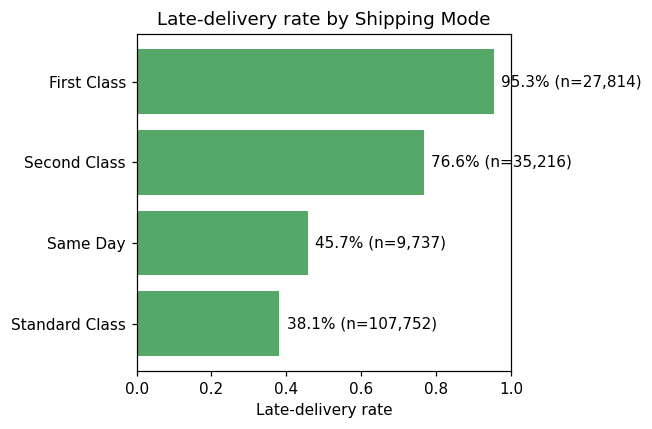

In [6]:
display(Image(filename=str(figures_dir / "fig02_late_rate_by_shipping_mode.png")))

## 8. Numerical analysis

Comparing distributions of order-time numeric variables between
Late_delivery_risk = 0 and = 1.

In [7]:
numeric_cols = ["Days for shipment (scheduled)", "Order Item Quantity",
                "Order Item Product Price", "Order Item Discount",
                "Order Item Discount Rate", "Sales", "Order Item Total"]
for col in numeric_cols:
    stats = df.groupby("Late_delivery_risk")[col].describe()[["count", "mean", "50%", "std"]]
    print(f"--- {col} ---")
    print(stats)
    print()

--- Days for shipment (scheduled) ---
                      count      mean  50%       std
Late_delivery_risk                                  
0                   81542.0  3.491146  4.0  1.151072
1                   98977.0  2.471069  2.0  1.372540

--- Order Item Quantity ---
                      count      mean  50%       std
Late_delivery_risk                                  
0                   81542.0  2.127860  1.0  1.453282
1                   98977.0  2.127454  1.0  1.453598

--- Order Item Product Price ---
                      count        mean        50%         std
Late_delivery_risk                                            
0                   81542.0  141.567424  65.000000  141.266639
1                   98977.0  140.956665  59.990002  138.455924

--- Order Item Discount ---
                      count       mean    50%        std
Late_delivery_risk                                      
0                   81542.0  20.682753  14.04  21.937552
1                   989

--- Order Item Total ---
                      count        mean         50%         std
Late_delivery_risk                                             
0                   81542.0  183.609025  163.990005  121.428716
1                   98977.0  182.694518  163.990005  118.889507



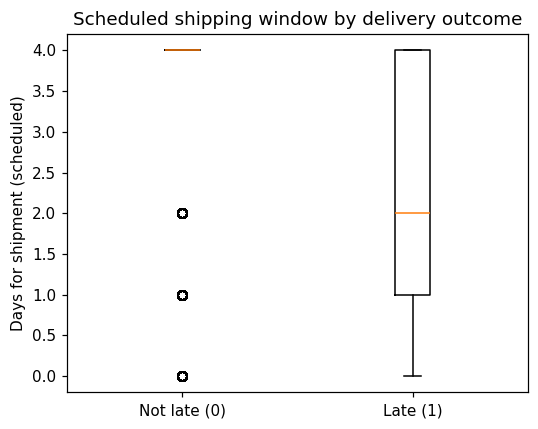

In [8]:
display(Image(filename=str(figures_dir / "fig03_scheduled_days_by_target.png")))

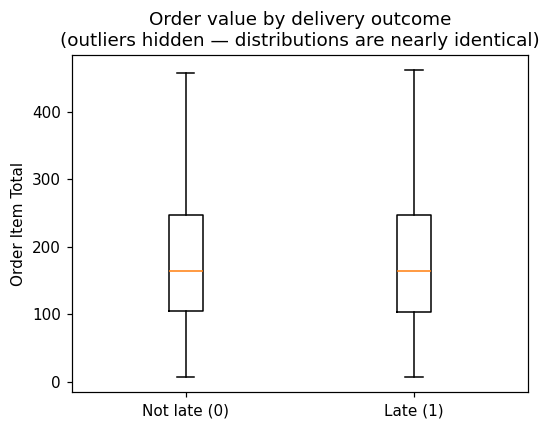

In [9]:
display(Image(filename=str(figures_dir / "fig08_order_item_total_by_target.png")))

**Observation:** `Days for shipment (scheduled)` differs meaningfully
between classes (mean 3.49 vs 2.47 days). All other numeric variables
checked (quantity, price, discount, sales, total) show almost no
difference between classes. **Interpretation:** order size/value does
not appear associated with lateness in this data; correlation is not
being assumed from these flat patterns, and no difference is not being
over-read as a strong negative finding either — it's simply what was
observed.

## 9. Temporal analysis

Using `order date (DateOrders)` only (available at prediction time) —
**not** `shipping date (DateOrders)`, which is leaky.

In [10]:
for col, label in [("order_year", "year"), ("order_month", "month"),
                    ("order_dow", "day of week"), ("order_hour", "hour")]:
    t = group_rate_table(df, col, "Late_delivery_risk")
    print(f"--- By {label}: rate range {t['positive_rate'].min():.4f} to {t['positive_rate'].max():.4f} ---")

--- By year: rate range 0.5445 to 0.5629 ---


--- By month: rate range 0.5406 to 0.5579 ---
--- By day of week: rate range 0.5430 to 0.5517 ---


--- By hour: rate range 0.5087 to 0.5950 ---


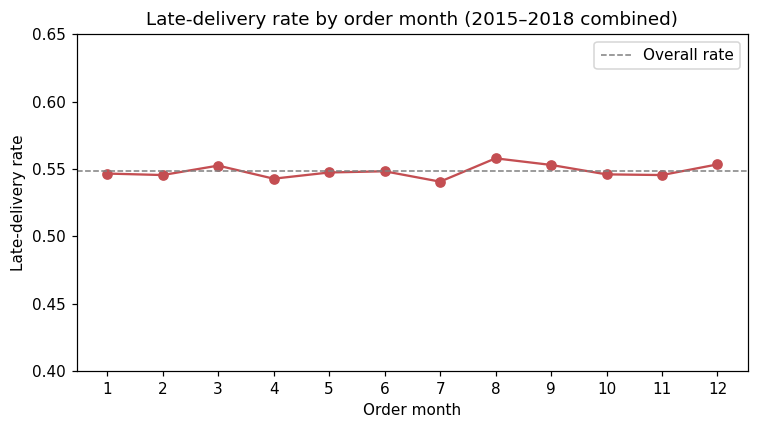

In [11]:
display(Image(filename=str(figures_dir / "fig04_late_rate_by_month.png")))

## 10. Geographic analysis

At `Order Region` granularity (23 categories — readable), not raw
`Order City`/`Order State` (thousands of categories, would be
unreadable and unstable).

In [12]:
region_table = group_rate_table(df, "Order Region", "Late_delivery_risk")
region_table = region_table.sort_values("sample_count", ascending=False)
print(region_table.to_string(index=False))
small_sample = region_table[region_table["sample_count"] < 2000]
print()
print("Regions with comparatively small sample sizes (rate less stable):")
print(small_sample[["Order Region", "sample_count", "positive_rate"]].to_string(index=False))

   Order Region  sample_count  positive_count  positive_rate  low_sample_warning
Central America         28341           15518         0.5475               False
 Western Europe         27109           15140         0.5585               False
  South America         14935            8111         0.5431               False
        Oceania         10148            5482         0.5402               False
Northern Europe          9792            5292         0.5404               False
 Southeast Asia          9539            5297         0.5553               False
Southern Europe          9431            5129         0.5438               False
      Caribbean          8318            4415         0.5308               False
   West of USA           7993            4313         0.5396               False
     South Asia          7731            4350         0.5627               False
   Eastern Asia          7280            3955         0.5433               False
    East of USA          691

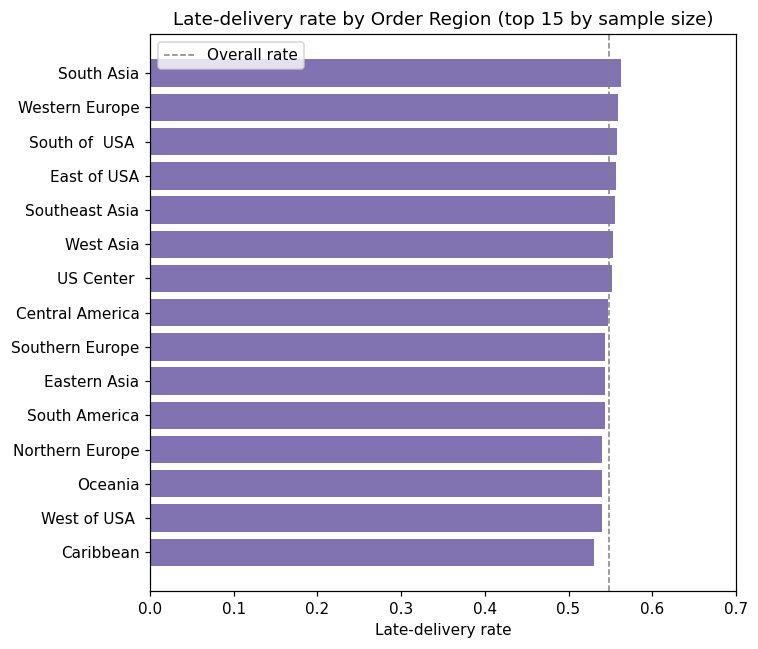

In [13]:
display(Image(filename=str(figures_dir / "fig05_late_rate_by_order_region.png")))

## 11. Shipping-mode investigation

Does `Shipping Mode` relate to `Days for shipment (scheduled)` — are
they encoding the same planning decision?

In [14]:
ct = pd.crosstab(df["Shipping Mode"], df["Days for shipment (scheduled)"])
print(ct)
print()
print(df.groupby("Shipping Mode")["Days for shipment (scheduled)"].nunique())

Days for shipment (scheduled)     0      1      2       4
Shipping Mode                                            
First Class                       0  27814      0       0
Same Day                       9737      0      0       0
Second Class                      0      0  35216       0
Standard Class                    0      0      0  107752



Shipping Mode
First Class       1
Same Day          1
Second Class      1
Standard Class    1
Name: Days for shipment (scheduled), dtype: int64


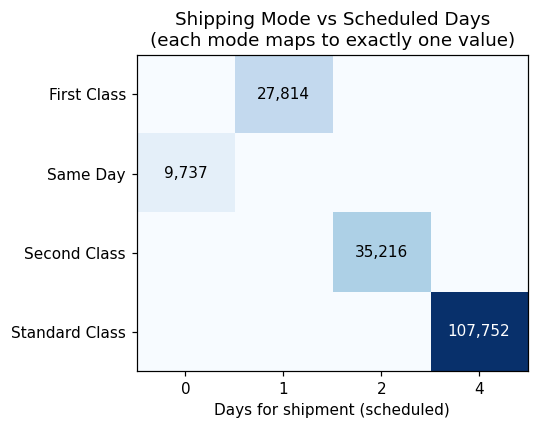

In [15]:
display(Image(filename=str(figures_dir / "fig06_shipping_mode_vs_scheduled_days.png")))

**Observation:** each `Shipping Mode` value maps to exactly one
`Days for shipment (scheduled)` value, with zero exceptions.
**Interpretation:** these columns are not independent — they represent
one underlying planning decision, not two. We do not call the
mode-lateness relationship causal; it more likely reflects that a
shorter promised window (e.g. First Class = 1 day) leaves less slack
before a shipment is counted as "late."

## 12. Leakage demonstration (educational — not a model)

Comparing the PLANNED duration against the ACTUAL duration, by target
class, to make the leakage issue concrete.

In [16]:
for col in ["Days for shipment (scheduled)", "Days for shipping (real)"]:
    print(f"--- {col} ---")
    print(df.groupby("Late_delivery_risk")[col].describe()[["count", "mean", "50%", "std"]])
    print()

diff = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
print("real - scheduled, by target class:")
print(diff.groupby(df["Late_delivery_risk"]).describe()[["mean", "50%", "min", "max"]])

--- Days for shipment (scheduled) ---
                      count      mean  50%       std
Late_delivery_risk                                  
0                   81542.0  3.491146  4.0  1.151072
1                   98977.0  2.471069  2.0  1.372540

--- Days for shipping (real) ---
                      count      mean  50%       std
Late_delivery_risk                                  
0                   81542.0  2.779561  3.0  1.162392
1                   98977.0  4.089253  5.0  1.708971

real - scheduled, by target class:
                        mean  50%  min  max
Late_delivery_risk                         
0                  -0.711584 -1.0 -2.0  4.0
1                   1.618184  1.0  1.0  4.0


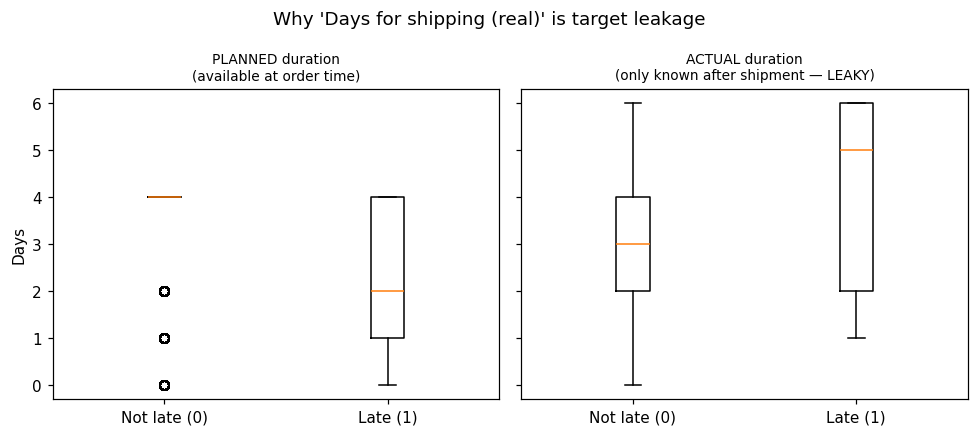

In [17]:
display(Image(filename=str(figures_dir / "fig07_leakage_real_vs_scheduled_by_target.png")))

For every row where `Late_delivery_risk == 1`, `real - scheduled >= 1`
(shipment took at least one day longer than planned) — this is *how the
outcome came to be labeled late* in the first place, not a pattern a
model would need to discover. This is why `Days for shipping (real)`
cannot be used as a feature.

## 13. Key findings

1. `Shipping Mode` (and its collinear twin `Days for shipment
   (scheduled)`) is by far the strongest observed signal — late rate
   ranges 38.1% to 95.3% across modes.
2. Market, Customer Segment, Order Region, and Type show comparatively
   flat late rates (all within roughly 10 points of the 54.8% overall
   average).
3. Order-value numeric fields (price, quantity, discount, sales, total)
   show no observed relationship with lateness.
4. Temporal features (year/month/day-of-week/hour) show no observed
   relationship with lateness.
5. `Days for shipping (real)` and `shipping date (DateOrders)` are
   confirmed, demonstrable leakage — not just flagged by name/timing
   reasoning but shown numerically.
6. Three additional redundant column pairs were found this milestone
   beyond the three from Milestone 1.

## 14. Candidate feature recommendations

Full matrix: `artifacts/reports/feature_candidate_matrix.csv`. Summary
counts by recommendation:

In [18]:
matrix = pd.read_csv(resolve_path(config["paths"]["artifacts_reports"]) / "feature_candidate_matrix.csv")
matrix["future_model_recommendation"].value_counts()

future_model_recommendation
CONSIDER              15
EXCLUDE_PRIVACY       11
REVIEW                 8
EXCLUDE_REDUNDANT      6
EXCLUDE_IDENTIFIER     6
EXCLUDE_LEAKAGE        3
EXCLUDE_CONSTANT       3
EXCLUDE_TARGET         1
Name: count, dtype: int64

## 15. Limitations

- Single historical dataset (2015-2018, one source) — findings describe
  patterns in this data, not universal claims.
- `Order Zipcode` is 86.24% missing.
- Geography-field "customer vs. store" ambiguity could not be resolved
  from the data alone; treated conservatively (privacy-excluded).
- `Benefit per order` and related profit fields have unconfirmed
  operational timing — not analyzed against the target this milestone.
- Several `Order Region` categories have comparatively small sample
  sizes; their rates are less stable than large-sample regions.